In [1]:
%pip install seaborn
%pip install sentence_transformers

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached sentence_transformers-5.5.0-py3-none-any.whl.metadata (18 kB)
Using cached sentence_transformers-5.5.0-py3-none-any.whl (588 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
from pathlib import Path
from sentence_transformers import SentenceTransformer, util

c:\Users\joaol\OneDrive\Desktop\MestradoBaseMédica\ProjetoDoutorado\envmestradobasemedica\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:

env_path = Path('../../.env')
load_dotenv(dotenv_path=env_path)

True

In [4]:

print("Carregando modelo de Embeddings")
model = SentenceTransformer('paraphrase-multilingual-MiniLM-L12-v2')

Carregando modelo de Embeddings


In [5]:
caminhos = {
    "Corretor": "../../../BASES/experimento_corretor/analise_entropia/corretor_dados_anonimizados.csv",
    "BERTimbau": "../../../BASES/experimento_corretor/analise_entropia/bertimbau_entropy.csv",
    "spaCy": "../../../BASES/experimento_corretor/analise_entropia/spacy_entropy.csv"
}

In [6]:
resultados = []

In [7]:
for modelo_nome, caminho in caminhos.items():
    print(f"\n--- Processando modelo: {modelo_nome} ---")
    
    df = pd.read_csv(caminho)
    
    df['relato'] = df['relato'].astype(str)
    df['relato_anon'] = df['relato_anon'].astype(str)
    
    textos_orig = df['relato'].tolist()
    textos_anon = df['relato_anon'].tolist()
    
    print("Gerando embeddings dos relatos originais...")
    emb_orig = model.encode(textos_orig, convert_to_tensor=True, show_progress_bar=True)
    
    print("Gerando embeddings dos relatos anonimizados...")
    emb_anon = model.encode(textos_anon, convert_to_tensor=True, show_progress_bar=True)
    
    print("Calculando Similaridade por Cosseno...")
    cosseno_scores = util.cos_sim(emb_orig, emb_anon)
    
    similaridades = np.diag(cosseno_scores.cpu().numpy())
    
    media = similaridades.mean()
    std = similaridades.std()
    
    resultados.append({
        "Modelo": modelo_nome,
        "Similaridade_Cosseno_Media": media,
        "Similaridade_Percentual": media * 100,
        "Desvio_Padrao": std
    })


--- Processando modelo: Corretor ---
Gerando embeddings dos relatos originais...


Batches: 100%|██████████| 59/59 [00:23<00:00,  2.52it/s]


Gerando embeddings dos relatos anonimizados...


Batches: 100%|██████████| 59/59 [00:21<00:00,  2.74it/s]


Calculando Similaridade por Cosseno...

--- Processando modelo: BERTimbau ---
Gerando embeddings dos relatos originais...


...

Calculando Similaridade por Cosseno...

--- Processando modelo: spaCy ---
Gerando embeddings dos relatos originais...


Batches: 100%|██████████| 59/59 [00:22<00:00,  2.62it/s]


Gerando embeddings dos relatos anonimizados...


Batches: 100%|██████████| 59/59 [00:21<00:00,  2.71it/s]

Calculando Similaridade por Cosseno...


In [8]:
df_resultados = pd.DataFrame(resultados)
print("\n" + "="*50)
print("🏆 RESULTADO FINAL - RETENÇÃO DE UTILIDADE (SEMÂNTICA) 🏆")
print("="*50)
print(df_resultados[['Modelo', 'Similaridade_Percentual', 'Desvio_Padrao']])
print("="*50)


🏆 RESULTADO FINAL - RETENÇÃO DE UTILIDADE (SEMÂNTICA) 🏆
      Modelo  Similaridade_Percentual  Desvio_Padrao
0   Corretor                70.263962       0.087686
1  BERTimbau                92.823448       0.042449
2      spaCy                93.277184       0.046166


In [9]:
df_resultados.to_csv("../../../BASES/experimento_corretor/avaliacao_modelos/comparativo_cosseno_final.csv", index=False)

C:\Users\joaol\AppData\Local\Temp\ipykernel_32816\3254146954.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x='Modelo', y='Similaridade_Percentual', data=df_resultados, palette='viridis')


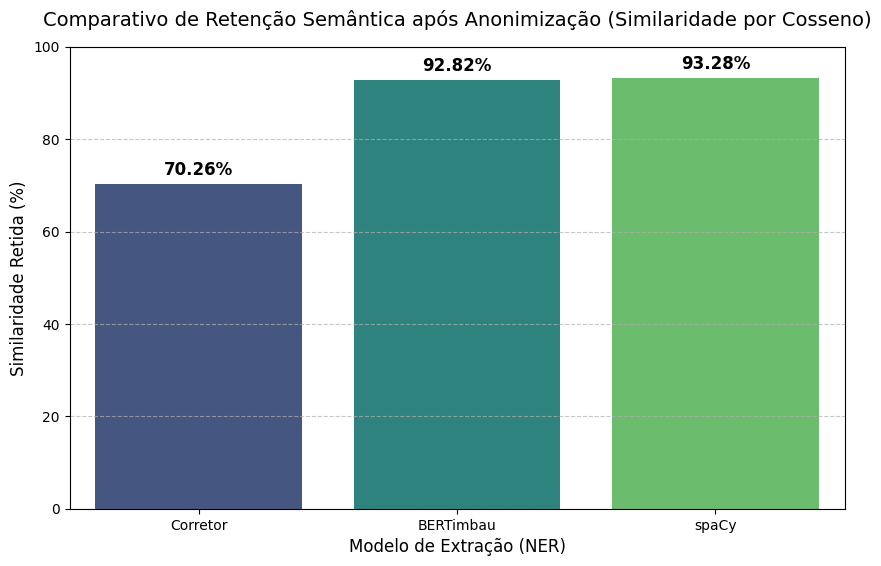

In [10]:
plt.figure(figsize=(10, 6))
ax = sns.barplot(x='Modelo', y='Similaridade_Percentual', data=df_resultados, palette='viridis')

for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}%", 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', xytext=(0, 10), 
                textcoords='offset points', fontsize=12, fontweight='bold')

plt.ylim(0, 100)
plt.title('Comparativo de Retenção Semântica após Anonimização (Similaridade por Cosseno)', fontsize=14, pad=15)
plt.ylabel('Similaridade Retida (%)', fontsize=12)
plt.xlabel('Modelo de Extração (NER)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)   

In [11]:
plt.savefig("../../images/grafico_similaridade_cosseno.png", bbox_inches='tight', dpi=300)
plt.show()

print("\nGráfico exportado com sucesso para a pasta 'images'!")

<Figure size 640x480 with 0 Axes>


Gráfico exportado com sucesso para a pasta 'images'!
